# ABP production: chain errors, active work, and orientation

A **standalone notebook** in the style of `plot_speed_sweep.ipynb` and
`plot_abp_TD_sweep.ipynb`. All analysis functions are included below.

1. Edit **User configuration** and select one or several production run folders.
2. Run all cells from the top.
3. Inspect the case inventory, PDFs, occupation maps, slice comparisons, and work tables.

The physical PDFs use the saved MUCA **reweighted masses**. Error bands delete one
complete production chain at a time, removing its numerator and denominator together.
`BAND_SIGMA=1` displays one standard error; `1.96` gives approximate pointwise 95% bands.
An unvisited bin has no empirical uncertainty estimate; it is not evidence of exactly zero probability.

The path maps condition on **$x(T)>0.5$** and pool the physical-time points retained by
production. They estimate occupation distributions, not distributions at a chosen fixed time.
The $x$ slices are selected at the saved histogram-bin resolution. Angular densities
use radians and $	heta\bmod 2\pi\in[0,2\pi)$.

New Julia production outputs are needed for chain errors, active work, and orientation.
Older files can still supply their saved endpoint curves and diagnostics; unavailable
sections are reported explicitly. No `chain_errors_active_work.py` import is required.


## 1. Imports

If an import is missing, uncomment the installation line, run the cell, then restart
the kernel. Only ordinary Python scientific packages are needed.


In [1]:
# %pip install numpy pandas matplotlib h5py

from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.ticker import MaxNLocator, StrMethodFormatter

try:
    import h5py
except ImportError as exc:
    raise ImportError("Install h5py in this notebook's kernel: y%pip install h5py") from exc

try:
    from IPython.display import display
except ImportError:
    display = print

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 220,
    "axes.grid": True,
    "grid.alpha": 0.22,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "font.size": 10,
})


## 2. User configuration

Place this notebook beside your existing notebooks in `ABPNoiseSweep/`.
Set `PROJECT_ROOT` explicitly if Jupyter starts in another directory.

`RUN_ROOTS` accepts multiple job folders; the search is recursive and reads actual
metadata from each `.jld2`. Alternatively list exact files in `JLD2_FILES`.
For a speed sweep use `SWEEP_PARAMETER="v"` and a chosen `D_SELECT`.
For a noise sweep use `SWEEP_PARAMETER="D"`, `D_SELECT=None`, and a chosen `V_SELECT`.
Other physical parameters are kept separate in work comparisons.

`X_SLICES` changes both the $y$ and $	heta$ slice plots. `Y_DISPLAY` and `X_DISPLAY`
only crop figure axes; they do not renormalize PDFs. `M_CUT` defines the work routes
from the first-crossing ordinate and is independent of the occupation slices.


In [2]:
PROJECT_ROOT = Path.cwd()
# PROJECT_ROOT = Path("/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNoiseSweep")

RUN_ROOTS = [
    "data/abp_work_theta_D0p025_array_1868220"
]
JLD2_FILES = []  # Optional exact files. When nonempty, replaces RUN_ROOTS discovery.
JOB_IDS = []     # Optional path filter, e.g. ["NEW_JOB_1", "NEW_JOB_2"].
                # Leave empty for legacy output paths that contain no job ID.

SWEEP_PARAMETER = "v"  # "v" for speed; "D" for noise
D_SELECT = 0.025       # None keeps all noise levels
V_SELECT = None        # e.g. 0.330; None keeps all speeds
T_SELECT = None        # e.g. 40.0; None keeps all durations

# Only endpoint-observable plots use ENDPOINT_WINDOW. The path/work condition
# is fixed by the saved statistics to x(T)>0.5.
ENDPOINT_WINDOW = "x_gt_0p5"
X_SLICES = {
    "upstream": (-0.40, -0.20),
    "crossing": (-0.05, 0.05),
}
M_CUT = 0.5
BAND_SIGMA = 1.0

X_DISPLAY = (-1.0, 1.2)
Y_DISPLAY = (-2.0, 2.0)
LOG_HEATMAP = True
MAX_DETAILED_CASES = 6  # Evenly spaced cases for maps and trajectory examples
MAX_EXAMPLE_PATHS = 3

SAVE_FIGS = True
SAVE_TABLES = True
SHOW_FIGS = True
FIG_FORMATS = ("png", "pdf")
OUTPUT_DIR = PROJECT_ROOT / "data" / "plots_production_errors_work_theta"

## 3. Reweighting and chain jackknife

For each histogram bin, normalize the **pooled masses**, not the average of normalized
chain PDFs. With $C$ chains and a ratio $R=N/Z$, the delete-one estimates are
$R_{(-c)}=(N-N_c)/(Z-Z_c)$. The standard error is

$$\mathrm{SE}_{\rm JK}=\sqrt{\frac{C-1}{C}\sum_c
\left(R_{(-c)}-\overline{R}_{(-\cdot)}\right)^2}.$$

Zero-contribution chains remain in the calculation. Empty slices or undefined
delete-one denominators produce `NaN`, not invented error bars. These errors measure
between-chain production variation with the learned bias held fixed. Shared lack of
equilibration, finite integration step, binning, and route-cut choices need separate checks.


In [3]:
def vector(h5, key):
    return np.asarray(h5[key], dtype=float).reshape(-1)


def scalar(h5, key, default=np.nan):
    if key not in h5:
        return default
    value = np.asarray(h5[key])
    if value.size != 1:
        raise ValueError(f"Expected a scalar at {key}, got {value.shape}")
    return float(value.reshape(-1)[0])


def checked_edges(h5, key):
    edges = vector(h5, key)
    if len(edges) < 2 or not np.all(np.isfinite(edges)) or np.any(np.diff(edges) <= 0):
        raise ValueError(f"Invalid histogram edges: {key}")
    return edges


def jackknife_ratio(numerator, denominator):
    numerator, denominator = np.broadcast_arrays(
        np.asarray(numerator, dtype=float), np.asarray(denominator, dtype=float)
    )
    if numerator.ndim < 1:
        raise ValueError("Axis 0 must identify the production chains")
    if not np.all(np.isfinite(numerator)) or not np.all(np.isfinite(denominator)):
        raise ValueError("Nonfinite chain sufficient statistics")
    if np.any(denominator < 0):
        raise ValueError("Negative reweighting denominator")
    n = numerator.shape[0]
    total_num, total_den = numerator.sum(axis=0), denominator.sum(axis=0)
    value = np.divide(total_num, total_den,
                      out=np.full_like(total_num, np.nan), where=total_den > 0)
    if n < 2:
        return value, np.full_like(value, np.nan)
    den = total_den - denominator
    deleted = np.divide(total_num - numerator, den,
                        out=np.full_like(numerator, np.nan), where=den > 0)
    variance = (n - 1) / n * np.sum((deleted - deleted.mean(axis=0))**2, axis=0)
    se = np.where(np.all(np.isfinite(deleted), axis=0),
                  np.sqrt(np.maximum(variance, 0)), np.nan)
    return value, se


def pdf_from_mass(mass, edges, *, chain_resolved=True):
    mass = np.asarray(mass, dtype=float)
    edges = np.asarray(edges, dtype=float)
    if mass.ndim == 1:
        mass = mass[None, :]
    if mass.ndim != 2 or mass.shape[1] != len(edges) - 1:
        raise ValueError("Expected mass shape (chains, bins)")
    if not np.all(np.isfinite(mass)) or np.any(mass < 0):
        raise ValueError("Histogram masses must be finite and nonnegative")
    widths = np.diff(edges)
    if np.any(widths <= 0):
        raise ValueError("Bin edges must be strictly increasing")
    density, se = jackknife_ratio(mass, mass.sum(axis=1, keepdims=True) * widths)
    total = mass.sum(axis=0)
    if not chain_resolved:
        se[:] = np.nan
    se = np.where(total > 0, se, np.nan)  # No measured precision for unseen bins.
    return pd.DataFrame({
        "left": edges[:-1], "right": edges[1:], "center": (edges[:-1] + edges[1:]) / 2,
        "width": widths, "unbiased_mass": total, "unbiased_pdf": density,
        "chain_jackknife_se": se,
        "band_low": np.maximum(0, density - BAND_SIGMA * se),
        "band_high": density + BAND_SIGMA * se,
        "relative_se": np.divide(se, density, out=np.full_like(se, np.nan), where=density > 0),
        "n_chains_with_bin_mass": (mass > 0).sum(axis=0) if chain_resolved else np.nan,
        "n_chains_with_slice_mass": int(np.count_nonzero(mass.sum(axis=1))) if chain_resolved else np.nan,
    })


def chain_ids(h5):
    base = "chain_statistics/chains"
    if base not in h5:
        return []
    ids = sorted(h5[base].keys(), key=int)
    expected = int(scalar(h5, "chain_statistics/n_chains", len(ids)))
    if len(ids) != expected:
        raise ValueError(f"Expected {expected} chains, found {len(ids)}")
    return ids


def read_chain_matrix(h5, chain_id, field):
    base = f"chain_statistics/chains/{chain_id}/path_endpoint_conditions/x_gt_0p5/unbiased"
    shape = np.asarray(h5[f"{base}/{field}_shape"], dtype=int).reshape(-1)
    flat = vector(h5, f"{base}/{field}_flat_julia_column_major")
    if len(shape) != 2 or np.any(shape <= 0) or np.prod(shape) != flat.size:
        raise ValueError(f"Invalid matrix shape for chain {chain_id}: {shape}")
    # Explicit Julia vec() output: axis order remains (x, y) or (x, theta).
    matrix = flat.reshape(tuple(shape), order="F")
    if not np.all(np.isfinite(matrix)) or np.any(matrix < 0):
        raise ValueError(f"Invalid path masses in chain {chain_id}")
    return matrix


## 4. Discover cases and inspect actual saved settings

Repeated paths are deduplicated. Different files at the same $(D,v,T)$ remain
separate cases: they are not silently pooled, since their MUCA weight shifts and
chain initialization may differ. The labels `C001`, `C002`, … identify the exact files.


In [4]:
def discover_production_files():
    if JLD2_FILES:
        files = [Path(p).expanduser().resolve() for p in JLD2_FILES]
    else:
        files = []
        for root in RUN_ROOTS:
            root = Path(root).expanduser()
            if root.is_file():
                files.append(root.resolve())
            elif root.is_dir():
                files.extend(p.resolve() for p in root.rglob("abp_endpoint_conditioned_*.jld2"))
            else:
                print(f"Run folder not found: {root}")
    files = sorted(set(files))
    if JOB_IDS:
        files = [p for p in files if any(str(job) in str(p) for job in JOB_IDS)]
    if not files:
        raise FileNotFoundError("No production JLD2 files found. Edit RUN_ROOTS or JLD2_FILES in cell 2. CSVs alone cannot provide the new chain errors.")
    return files


def read_case_metadata(file):
    with h5py.File(file, "r") as h5:
        required = ["metadata/D", "metadata/v", "metadata/trajectory_T", "histograms/bins_x_T"]
        if not all(key in h5 for key in required):
            return None
        ids = chain_ids(h5)
        base = f"chain_statistics/chains/{ids[0]}" if ids else "__absent__"
        row = dict(file=file, D=scalar(h5, "metadata/D"), v=scalar(h5, "metadata/v"),
                   T=scalar(h5, "metadata/trajectory_T"), n_chains=len(ids))
        for name in ["dt", "n_prod_obs_total", "path_observation_stride", "path_time_stride",
                     "active_work_observation_stride", "path_x_filter_min", "saved_path_time_thin"]:
            row[name] = scalar(h5, f"metadata/{name}")
        row["has_chain_endpoint"] = f"{base}/unbiased/x_T" in h5
        row["has_path_xy"] = f"{base}/path_endpoint_conditions/x_gt_0p5/unbiased/path_x_y_shape" in h5
        row["has_path_theta"] = f"{base}/path_endpoint_conditions/x_gt_0p5/unbiased/path_x_theta_shape" in h5
        row["has_work"] = f"{base}/active_work/unbiased/mass" in h5
        row["work_sampled"] = scalar(h5, "active_work/diagnostics/n_sampled")
        row["work_no_crossing"] = scalar(h5, "active_work/diagnostics/n_no_crossing")
        row["work_crossing_y_out"] = scalar(h5, "active_work/diagnostics/n_crossing_y_out")
        steps = [scalar(h5, f"chain_statistics/chains/{c}/n_steps") for c in ids]
        row["min_chain_steps"] = min(steps) if steps else np.nan
        row["max_chain_steps"] = max(steps) if steps else np.nan
        return row


if SWEEP_PARAMETER not in {"v", "D"}:
    raise ValueError("SWEEP_PARAMETER must be 'v' or 'D'")
if M_CUT < 0 or BAND_SIGMA <= 0 or MAX_DETAILED_CASES < 1 or MAX_EXAMPLE_PATHS < 1:
    raise ValueError("Check M_CUT, BAND_SIGMA, MAX_DETAILED_CASES, and MAX_EXAMPLE_PATHS")
for name, limits in X_SLICES.items():
    if len(limits) != 2 or not np.all(np.isfinite(limits)) or limits[0] >= limits[1]:
        raise ValueError(f"Invalid X_SLICES entry: {name}: {limits}")

CASES = []
for file in discover_production_files():
    try:
        row = read_case_metadata(file)
    except (OSError, ValueError) as exc:
        print(f"Skipped unreadable case {file}: {exc}")
        continue
    if row is None:
        continue
    if any(target is not None and not np.isclose(row[key], target, atol=1e-12, rtol=0)
           for key, target in [("D", D_SELECT), ("v", V_SELECT), ("T", T_SELECT)]):
        continue
    CASES.append(row)
CASES.sort(key=lambda c: (c[SWEEP_PARAMETER], c["D"], c["v"], c["T"], str(c["file"])))
if not CASES:
    raise RuntimeError("No cases match D_SELECT, V_SELECT, and T_SELECT. Check those filters.")
for i, case in enumerate(CASES, 1):
    case["case_id"] = f"C{i:03d}"
    case["label"] = f"{case['case_id']}: D={case['D']:g}, v={case['v']:g}, T={case['T']:g}"

inventory = pd.DataFrame(CASES)
display(inventory.drop(columns=["label"]))
duplicates = inventory.duplicated(["D", "v", "T"], keep=False)
if duplicates.any():
    print("Repeated (D,v,T) settings: retained as distinct files; work plots do not connect duplicate x values.")
    display(inventory.loc[duplicates, ["case_id", "D", "v", "T", "file"]])

pick = np.unique(np.linspace(0, len(CASES) - 1, min(MAX_DETAILED_CASES, len(CASES))).round().astype(int))
DETAIL_CASES = [CASES[i] for i in pick]
CASE_COLORS = {c["case_id"]: plt.colormaps["viridis"](q)
               for c, q in zip(CASES, np.linspace(0.05, 0.90, len(CASES)))}
FIGURES, TABLES, MESSAGES = [], [], []
if SAVE_FIGS or SAVE_TABLES:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Loaded {len(CASES)} case(s). Figure bands / work bars: {BAND_SIGMA:g} × chain-jackknife SE.")


,file,D,v,T,n_chains,dt,n_prod_obs_total,path_observation_stride,path_time_stride,active_work_observation_stride,...,has_chain_endpoint,has_path_xy,has_path_theta,has_work,work_sampled,work_no_crossing,work_crossing_y_out,min_chain_steps,max_chain_steps,case_id
0,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...,0.025,0.320,40.0,128,0.01,5.500000e+10,1000.0,1.0,10000.0,...,True,True,True,True,1201178.0,0.0,23.0,429687500.0,429687500.0,C001
1,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...,0.025,0.320,40.0,128,0.01,5.500000e+10,1000.0,1.0,10000.0,...,True,True,True,True,1201178.0,0.0,23.0,429687500.0,429687500.0,C002
2,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...,0.025,0.325,40.0,128,0.01,5.500000e+10,1000.0,1.0,10000.0,...,True,True,True,True,1388815.0,0.0,55.0,429687500.0,429687500.0,C003
3,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...,0.025,0.325,40.0,128,0.01,5.500000e+10,1000.0,1.0,10000.0,...,True,True,True,True,1388815.0,0.0,55.0,429687500.0,429687500.0,C004
4,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...,0.025,0.330,40.0,128,0.01,5.500000e+10,1000.0,1.0,10000.0,...,True,True,True,True,1204881.0,0.0,46.0,429687500.0,429687500.0,C005
5,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...,0.025,0.330,40.0,128,0.01,5.500000e+10,1000.0,1.0,10000.0,...,True,True,True,True,1204881.0,0.0,46.0,429687500.0,429687500.0,C006
6,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...,0.025,0.335,40.0,128,0.01,5.500000e+10,1000.0,1.0,10000.0,...,True,True,True,True,1244933.0,0.0,69.0,429687500.0,429687500.0,C007
7,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...,0.025,0.335,40.0,128,0.01,5.500000e+10,1000.0,1.0,10000.0,...,True,True,True,True,1244933.0,0.0,69.0,429687500.0,429687500.0,C008
8,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...,0.025,0.340,40.0,128,0.01,5.500000e+10,1000.0,1.0,10000.0,...,True,True,True,True,1291661.0,0.0,67.0,429687500.0,429687500.0,C009
9,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...,0.025,0.340,40.0,128,0.01,5.500000e+10,1000.0,1.0,10000.0,...,True,True,True,True,1291661.0,0.0,67.0,429687500.0,429687500.0,C010


Repeated (D,v,T) settings: retained as distinct files; work plots do not connect duplicate x values.


,case_id,D,v,T,file
0,C001,0.025,0.320,40.0,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...
1,C002,0.025,0.320,40.0,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...
2,C003,0.025,0.325,40.0,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...
3,C004,0.025,0.325,40.0,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...
4,C005,0.025,0.330,40.0,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...
5,C006,0.025,0.330,40.0,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...
6,C007,0.025,0.335,40.0,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...
7,C008,0.025,0.335,40.0,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...
8,C009,0.025,0.340,40.0,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...
9,C010,0.025,0.340,40.0,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...


Loaded 30 case(s). Figure bands / work bars: 1 × chain-jackknife SE.


## 5. Plot and export helpers

Figures are saved as PNG and PDF, and numerical results as CSV. The CSV standard
errors always represent **one** standard error, regardless of the display multiplier.


In [5]:
def safe_tag(text):
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", str(text)).strip("_")


def note(case, message):
    text = f"{case['case_id']}: {message}"
    if text not in MESSAGES:
        MESSAGES.append(text)
        print(text)


def export_table(table, name):
    if SAVE_TABLES and not table.empty:
        path = OUTPUT_DIR / f"{safe_tag(name)}.csv"
        table.to_csv(path, index=False)
        if path not in TABLES:
            TABLES.append(path)


from matplotlib.colors import Normalize

SPEED_CMAP = plt.colormaps["viridis"]
_speed_values = np.array([case["v"] for case in CASES], dtype=float)
if np.allclose(_speed_values, _speed_values[0]):
    SPEED_NORM = Normalize(_speed_values[0] - 0.5, _speed_values[0] + 0.5)
else:
    SPEED_NORM = Normalize(_speed_values.min(), _speed_values.max())
CASE_COLORS = {case["case_id"]: SPEED_CMAP(SPEED_NORM(case["v"])) for case in CASES}


def add_speed_colorbar(fig, axes):
    """Add one continuous colorbar for the speed encoded by all case curves."""
    mappable = plt.cm.ScalarMappable(norm=SPEED_NORM, cmap=SPEED_CMAP)
    mappable.set_array(_speed_values)
    cax = fig.add_axes([0.945, 0.16, 0.018, 0.70])
    fig.colorbar(mappable, cax=cax, label=r"Speed $v$")
    fig._speed_colorbar = True


def add_figure_legend(fig, axes, *, ncol=5, fontsize=7):
    """Place one deduplicated case legend below the axes."""
    handles, labels = [], []
    for ax in np.atleast_1d(axes).flat:
        for handle, label in zip(*ax.get_legend_handles_labels()):
            if label and label not in labels:
                handles.append(handle)
                labels.append(label)
        legend = ax.get_legend()
        if legend is not None:
            legend.remove()
    if not labels:
        return
    ncol = min(ncol, len(labels))
    rows = int(np.ceil(len(labels) / ncol))
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.005),
               ncol=ncol, frameon=False, fontsize=fontsize,
               handlelength=1.8, columnspacing=1.2, labelspacing=0.45)
    fig._case_legend_bottom = min(0.20 + 0.045 * rows, 0.50)


def finish_figure(fig, name):
    if hasattr(fig, "_case_legend_bottom"):
        fig.subplots_adjust(left=0.07, right=0.98, top=0.91,
                            bottom=fig._case_legend_bottom, wspace=0.28, hspace=0.34)
    elif hasattr(fig, "_speed_colorbar"):
        fig.subplots_adjust(left=0.07, right=0.92, top=0.91,
                            bottom=0.14, wspace=0.30, hspace=0.34)
    else:
        fig.tight_layout()
    if SAVE_FIGS:
        for ext in FIG_FORMATS:
            path = OUTPUT_DIR / f"{safe_tag(name)}.{ext}"
            fig.savefig(path, bbox_inches="tight")
            if path not in FIGURES:
                FIGURES.append(path)
    if SHOW_FIGS:
        plt.show()
    plt.close(fig)


def add_pdf(ax, table, case, label=None):
    color = CASE_COLORS[case["case_id"]]
    ax.plot(table["center"], table["unbiased_pdf"], color=color,
            label=label or case["label"], lw=1.6)
    ax.fill_between(table["center"].to_numpy(), table["band_low"].to_numpy(),
                    table["band_high"].to_numpy(), color=color, alpha=0.20, linewidth=0)


def theta_axis(ax, axis="x"):
    values = [0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi]
    labels = ["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"]
    if axis == "x":
        ax.set_xticks(values, labels)
        ax.set_xlim(0, 2 * np.pi)
    else:
        ax.set_yticks(values, labels)
        ax.set_ylim(0, 2 * np.pi)


def histogram_pdf(h5, edge_key, chain_suffix, pooled_key):
    edges = checked_edges(h5, edge_key)
    ids = chain_ids(h5)
    paths = [f"chain_statistics/chains/{c}/{chain_suffix}" for c in ids]
    if paths and all(p in h5 for p in paths):
        mass = np.stack([vector(h5, p) for p in paths])
        return pdf_from_mass(mass, edges), True
    if pooled_key not in h5:
        return None, False
    return pdf_from_mass(vector(h5, pooled_key), edges, chain_resolved=False), False


export_table(inventory, "case_inventory")

## 6. MUCA and production diagnostics

These plots read numerical datasets directly from the selected JLD2 files. They
retain the convergence and round-trip checks used in the earlier notebooks.


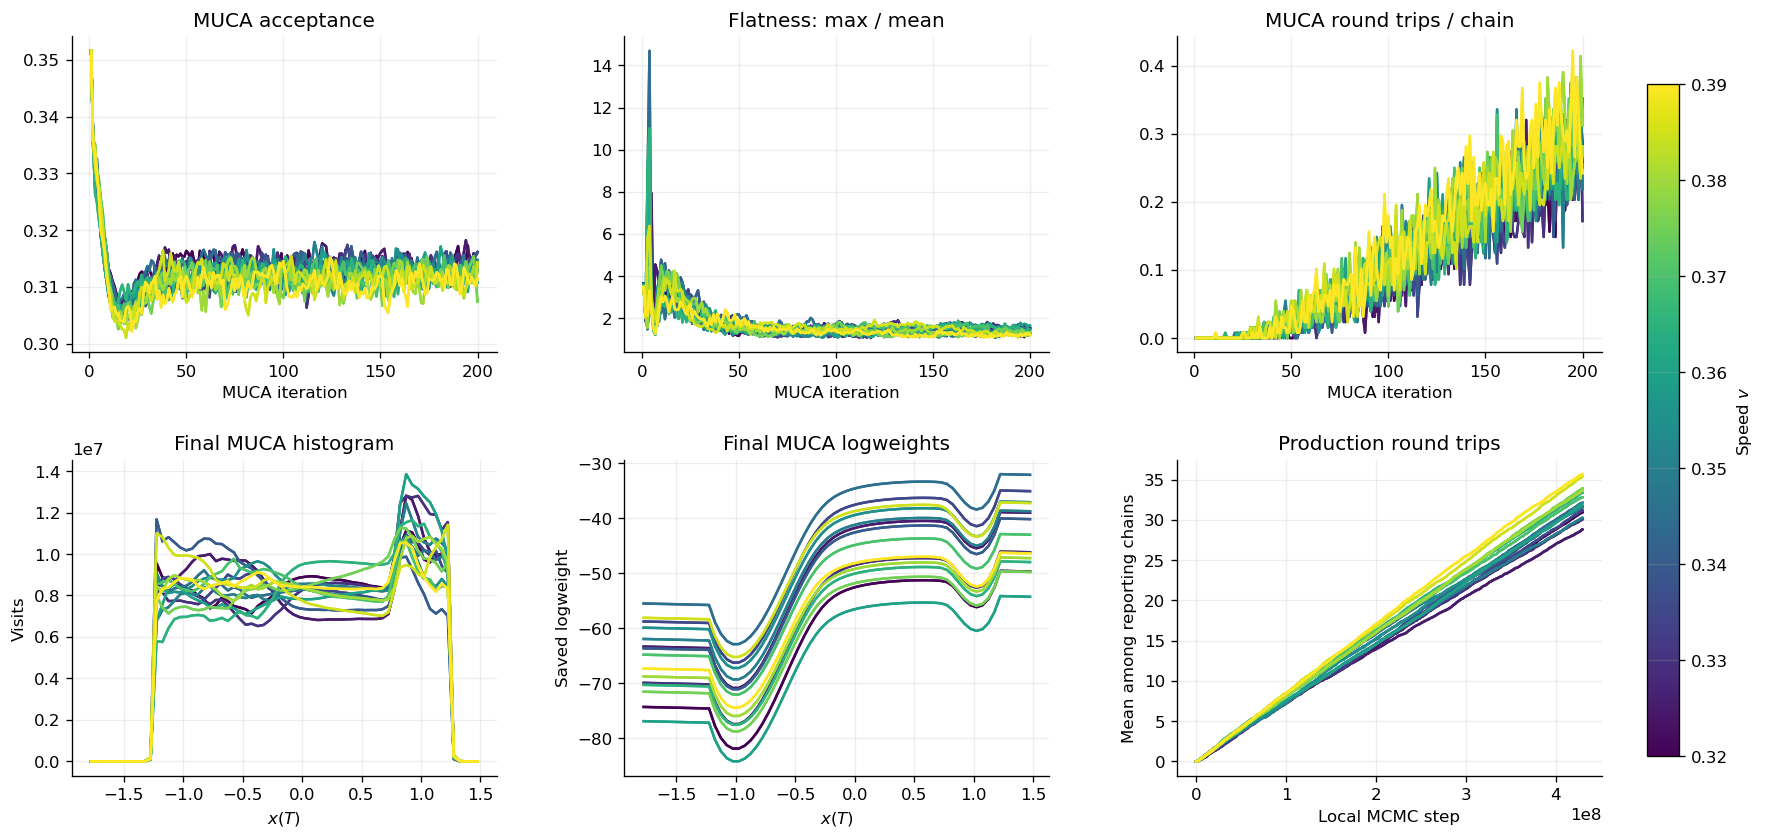

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
diagnostic_keys = [
    ("muca/iter_accept", "MUCA acceptance"),
    ("muca/iter_flatness_maxmean", "Flatness: max / mean"),
    ("muca/iter_avg_roundtrips_per_chain", "MUCA round trips / chain"),
]
for case in CASES:
    color = CASE_COLORS[case["case_id"]]
    with h5py.File(case["file"], "r") as h5:
        for ax, (key, title) in zip(axes[0], diagnostic_keys):
            if key in h5:
                values = vector(h5, key)
                ax.plot(np.arange(1, len(values) + 1), values, color=color)
            ax.set(title=title, xlabel="MUCA iteration")
        if "muca/centers_bias" in h5:
            centers = vector(h5, "muca/centers_bias")
            for ax, key in [(axes[1, 0], "muca/last_hist_values"), (axes[1, 1], "muca/last_logw_values")]:
                if key in h5:
                    ax.plot(centers, vector(h5, key), color=color)
        keys = ["roundtrips/chain_ids", "roundtrips/local_steps", "roundtrips/counts"]
        if all(k in h5 for k in keys):
            trace = pd.DataFrame({k.rsplit("/", 1)[1]: vector(h5, k) for k in keys})
            if not trace.empty:
                rt = trace.groupby("local_steps")["counts"].mean()
                axes[1, 2].plot(rt.index, rt.values, color=color)
        else:
            note(case, "Production round-trip trace unavailable.")
axes[1, 0].set(title="Final MUCA histogram", xlabel=r"$x(T)$", ylabel="Visits")
axes[1, 1].set(title="Final MUCA logweights", xlabel=r"$x(T)$", ylabel="Saved logweight")
axes[1, 2].set(title="Production round trips", xlabel="Local MCMC step", ylabel="Mean among reporting chains")
add_speed_colorbar(fig, axes)
finish_figure(fig, "muca_production_diagnostics")

## 7. Endpoint PDFs and endpoint-conditioned observables

The endpoint histogram gives $P(x(T))$. The other panels condition the trajectory
observables on `ENDPOINT_WINDOW`: $y(T)$, the saved mean $\bar y$, and
$\int y\,dt$. These are not path-point slices. Missing chain statistics permit a
pooled curve only; such a curve has no error band.


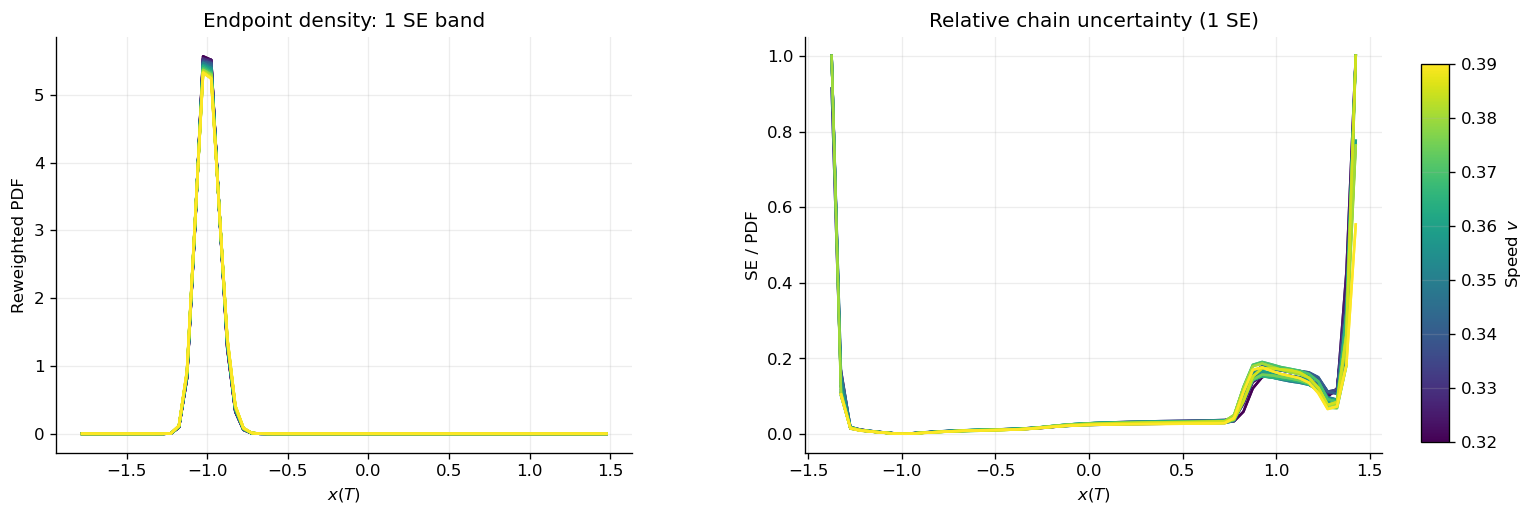

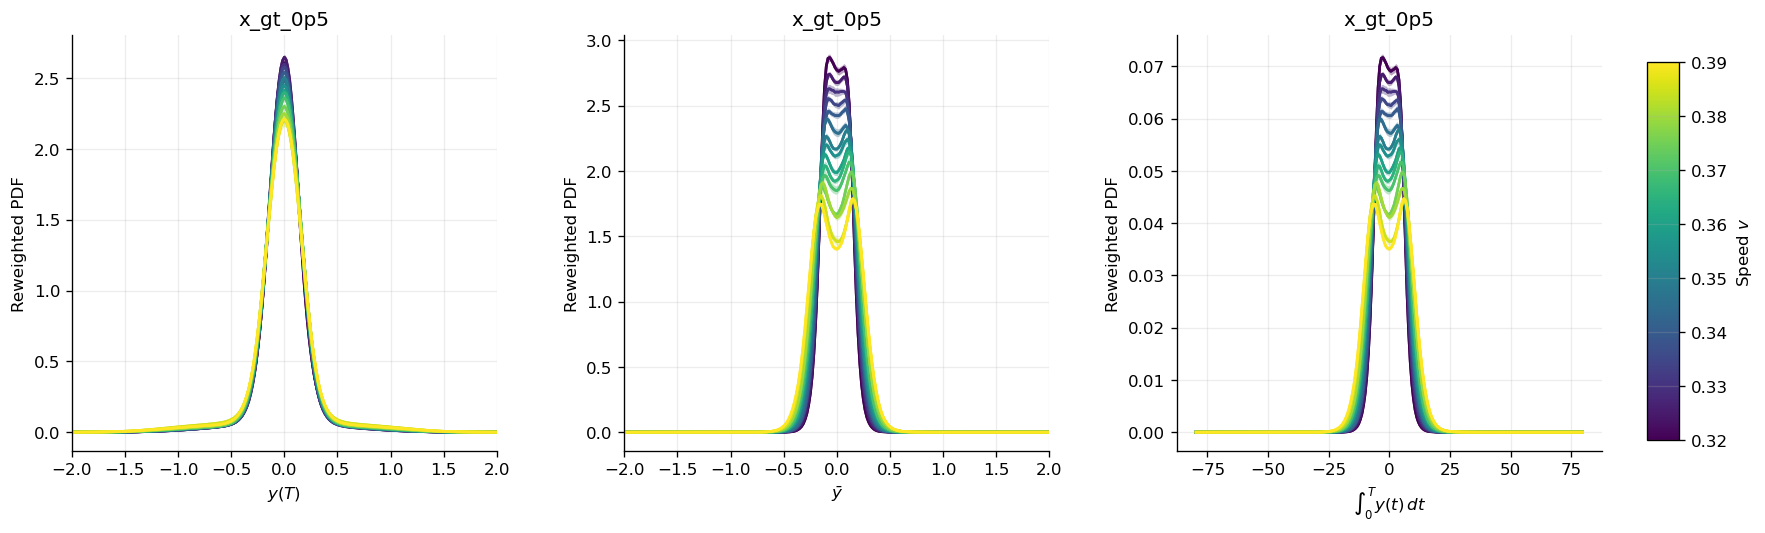

In [7]:
ENDPOINT_PDFS, CONDITIONAL_PDFS = {}, {}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for case in CASES:
    with h5py.File(case["file"], "r") as h5:
        table, has_chains = histogram_pdf(h5, "histograms/bins_x_T", "unbiased/x_T", "histograms/unbiased/x_T")
        if table is None:
            note(case, "Endpoint histogram unavailable.")
            continue
        if not has_chains or case["n_chains"] < 2:
            note(case, "Endpoint curve has no chain error band.")
        ENDPOINT_PDFS[case["case_id"]] = table
        add_pdf(axes[0], table, case, label="_")
        axes[1].plot(table["center"], table["relative_se"], color=CASE_COLORS[case["case_id"]])
        export_table(table, f"{case['case_id']}_endpoint_x_pdf")
axes[0].set(xlabel=r"$x(T)$", ylabel="Reweighted PDF", title=f"Endpoint density: {BAND_SIGMA:g} SE band")
axes[1].set(xlabel=r"$x(T)$", ylabel="SE / PDF", title="Relative chain uncertainty (1 SE)")
add_speed_colorbar(fig, axes)
finish_figure(fig, "endpoint_pdf_and_relative_error")

observables = [("y_T", r"$y(T)$"), ("y_mean", r"$\bar y$"), ("y_int", r"$\int_0^T y(t)\,dt$")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (observable, xlabel) in zip(axes, observables):
    for case in CASES:
        with h5py.File(case["file"], "r") as h5:
            if f"histograms/bins_{observable}" not in h5:
                continue
            table, has_chains = histogram_pdf(
                h5, f"histograms/bins_{observable}",
                f"conditional_windows/{ENDPOINT_WINDOW}/unbiased/{observable}",
                f"conditional_windows/{ENDPOINT_WINDOW}/unbiased/{observable}",
            )
        if table is None:
            note(case, f"Conditional window {ENDPOINT_WINDOW} / {observable} unavailable.")
            continue
        if not has_chains:
            note(case, f"{observable} conditional curve has no chain error band.")
        CONDITIONAL_PDFS[(case["case_id"], observable)] = table
        add_pdf(ax, table, case, label="_")
        export_table(table, f"{case['case_id']}_{ENDPOINT_WINDOW}_{observable}_pdf")
    ax.set(xlabel=xlabel, ylabel="Reweighted PDF", title=ENDPOINT_WINDOW)
    if observable in {"y_T", "y_mean"}:
        ax.set_xlim(*Y_DISPLAY)
    if not ax.lines:
        ax.text(0.5, 0.5, "Not saved", transform=ax.transAxes, ha="center")
add_speed_colorbar(fig, axes)
finish_figure(fig, f"conditional_observables_{ENDPOINT_WINDOW}")

## 8. Load the path maps and reduce each chain to the chosen slices

Both maps are conditioned on $x(T)>0.5$ and use the saved production path-point
filter. For each slice, the notebook sums the selected $x$ bins **within each chain**
before normalizing and constructing error bars. The `effective_x_lo` / `effective_x_hi`
columns show the full bins actually selected by their centers. The production filter
can additionally truncate the first retained bin.

Matrices are decoded from explicit Julia column-major vectors. The loader handles
one chain at a time, keeping only a pooled map and the much smaller slice arrays.
The $y$ and $\theta$ maps have their own saved ranges: out-of-range $y$ points can be
absent from the $x$–$y$ map while still contributing to the $x$–$\theta$ map.


In [8]:
def load_path_products(case, variable):
    field = {"y": "path_x_y", "theta": "path_x_theta"}[variable]
    with h5py.File(case["file"], "r") as h5:
        ids = chain_ids(h5)
        edge_key = f"histograms/bins_path_{variable}"
        shape_suffix = f"path_endpoint_conditions/x_gt_0p5/unbiased/{field}_shape"
        if not ids or edge_key not in h5 or not all(
            f"chain_statistics/chains/{c}/{shape_suffix}" in h5 for c in ids
        ):
            note(case, f"Chain-resolved x-{variable} histogram unavailable; section skipped.")
            return None
        x_edges = checked_edges(h5, "histograms/bins_path_x")
        z_edges = checked_edges(h5, edge_key)
        xc = (x_edges[:-1] + x_edges[1:]) / 2
        shape = (len(xc), len(z_edges) - 1)
        masks = {"all_saved_x": np.ones(len(xc), dtype=bool)}
        for name, (lo, hi) in X_SLICES.items():
            if name == "all_saved_x":
                raise ValueError("'all_saved_x' is reserved; choose another slice name")
            mask = (xc >= lo) & (xc < hi)
            if not mask.any():
                note(case, f"No saved x-bin centers in slice {name} [{lo}, {hi}); skipped.")
            else:
                masks[name] = mask
        pooled = np.zeros(shape)
        slice_masses = {name: np.zeros((len(ids), shape[1])) for name in masks}
        for ic, chain_id in enumerate(ids):
            matrix = read_chain_matrix(h5, chain_id, field)
            if matrix.shape != shape:
                raise ValueError(f"{field}: matrix {matrix.shape} does not match edges {shape}")
            pooled += matrix
            for name, mask in masks.items():
                slice_masses[name][ic] = matrix[mask, :].sum(axis=0)

    tables, diagnostics = {}, []
    for name, mass in slice_masses.items():
        mask = masks[name]
        selected = np.flatnonzero(mask)
        actual_lo, actual_hi = x_edges[selected[0]], x_edges[selected[-1] + 1]
        table = pdf_from_mass(mass, z_edges)
        table["effective_x_lo"], table["effective_x_hi"] = actual_lo, actual_hi
        tables[name] = table
        totals = mass.sum(axis=1)
        diagnostics.append(dict(
            case_id=case["case_id"], variable=variable, slice=name,
            requested_x_lo=X_SLICES[name][0] if name in X_SLICES else x_edges[0],
            requested_x_hi=X_SLICES[name][1] if name in X_SLICES else x_edges[-1],
            effective_x_lo=actual_lo, effective_x_hi=actual_hi,
            production_x_filter_min=case["path_x_filter_min"],
            n_x_bins=int(mask.sum()), n_chains_total=len(ids),
            n_chains_with_mass=int(np.count_nonzero(totals)),
            largest_chain_mass_fraction=totals.max() / totals.sum() if totals.sum() > 0 else np.nan,
            mass=float(totals.sum()),
            pdf_integral=float(np.sum(table["unbiased_pdf"] * table["width"])) if totals.sum() > 0 else np.nan,
        ))
        if totals.sum() <= 0:
            note(case, f"No observed {variable} mass in slice {name}.")
        elif np.count_nonzero(totals) < 2:
            note(case, f"Only one chain contributes to {variable} slice {name}; SE is undefined.")
    return dict(x_edges=x_edges, z_edges=z_edges, pooled_mass=pooled,
                pdfs=tables, diagnostics=diagnostics)


PATH_DATA = {"y": {}, "theta": {}}
slice_diagnostics = []
for case in CASES:
    for variable in PATH_DATA:
        product = load_path_products(case, variable)
        if product is not None:
            PATH_DATA[variable][case["case_id"]] = product
            slice_diagnostics.extend(product["diagnostics"])
            for name, table in product["pdfs"].items():
                export_table(table, f"{case['case_id']}_path_{variable}_{name}_pdf")
slice_diagnostics = pd.DataFrame(slice_diagnostics)
display(slice_diagnostics)
export_table(slice_diagnostics, "path_slice_diagnostics")


,case_id,variable,slice,requested_x_lo,requested_x_hi,effective_x_lo,effective_x_hi,production_x_filter_min,n_x_bins,n_chains_total,n_chains_with_mass,largest_chain_mass_fraction,mass,pdf_integral
0,C001,y,all_saved_x,-1.50,1.50,-1.500000,1.500000,-1.0,241,128,128,0.082856,0.033446,1.0
1,C001,y,upstream,-0.40,-0.20,-0.404564,-0.205394,-1.0,16,128,128,0.082885,0.000343,1.0
2,C001,y,crossing,-0.05,0.05,-0.056017,0.056017,-1.0,9,128,128,0.083485,0.000252,1.0
3,C001,theta,all_saved_x,-1.50,1.50,-1.500000,1.500000,-1.0,241,128,128,0.082856,0.033446,1.0
4,C001,theta,upstream,-0.40,-0.20,-0.404564,-0.205394,-1.0,16,128,128,0.082888,0.000343,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,C030,y,upstream,-0.40,-0.20,-0.404564,-0.205394,-1.0,16,128,128,0.079477,0.018808,1.0
176,C030,y,crossing,-0.05,0.05,-0.056017,0.056017,-1.0,9,128,128,0.079384,0.011057,1.0
177,C030,theta,all_saved_x,-1.50,1.50,-1.500000,1.500000,-1.0,241,128,128,0.087915,1.481065,1.0
178,C030,theta,upstream,-0.40,-0.20,-0.404564,-0.205394,-1.0,16,128,128,0.079479,0.018818,1.0


## 9. Matched $x$–$y$ and $x$–$\theta$ occupation maps

Each map is normalized over its full saved domain. Vertical shaded strips mark the
requested $x$ slices. The angle colorbar is a joint density per unit $x$ per radian.


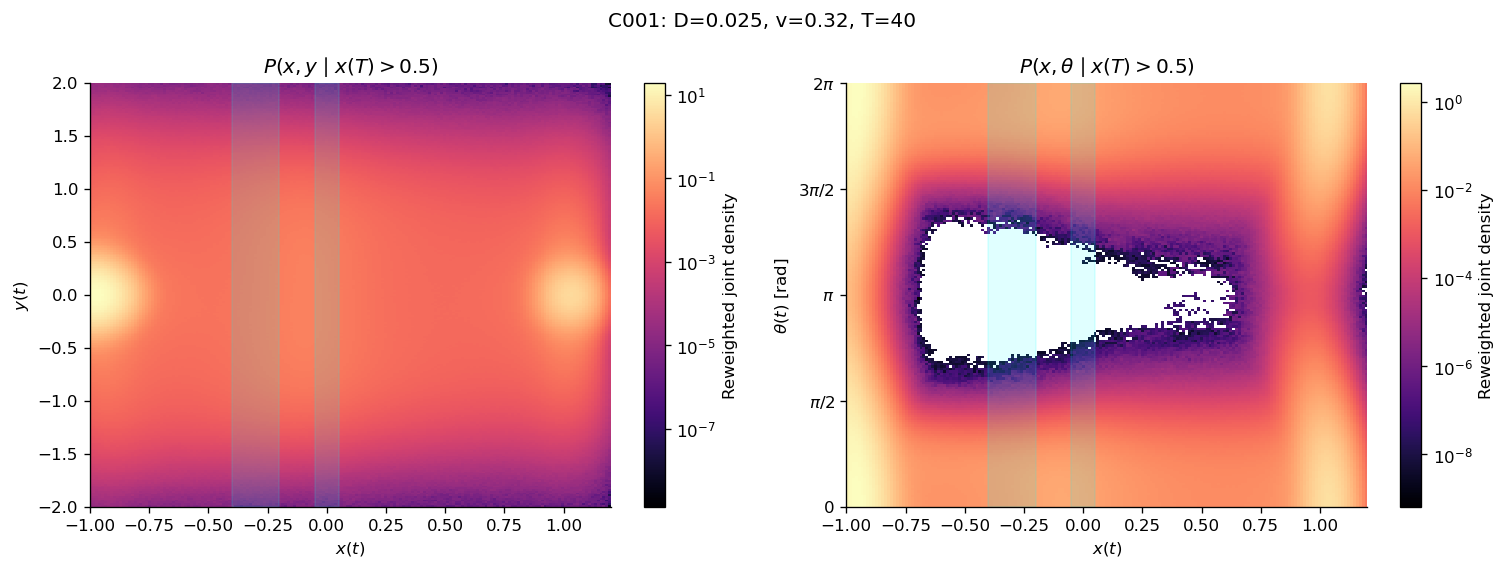

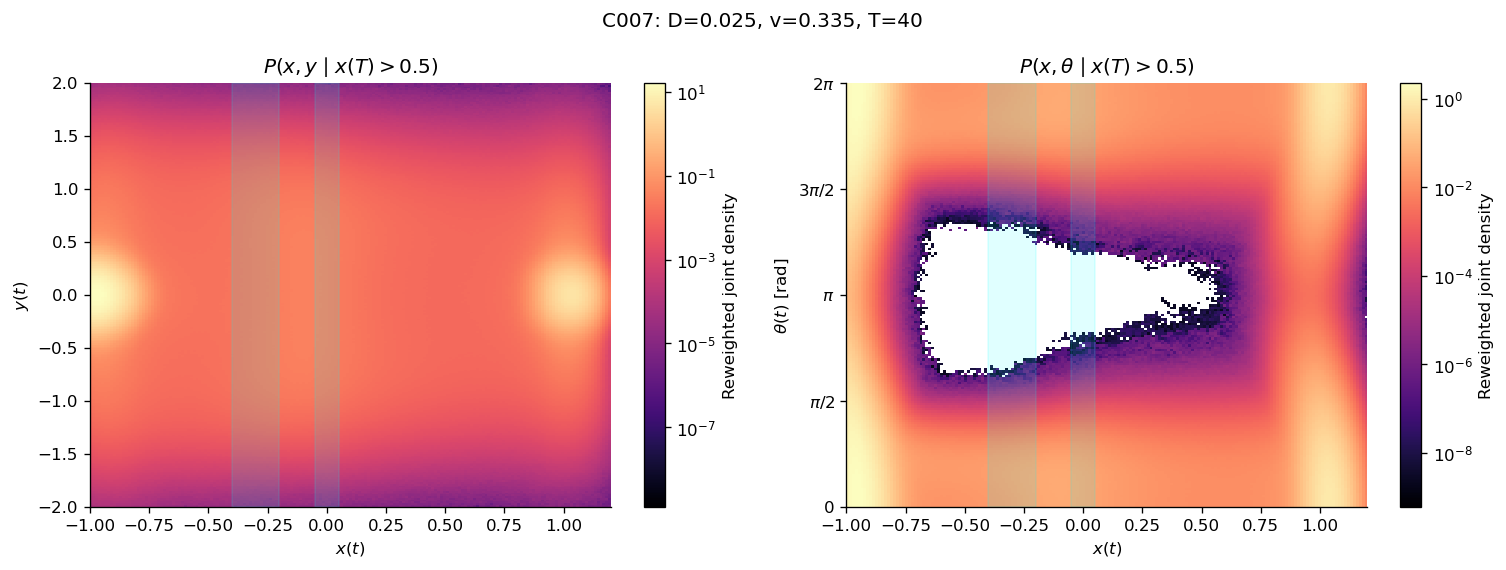

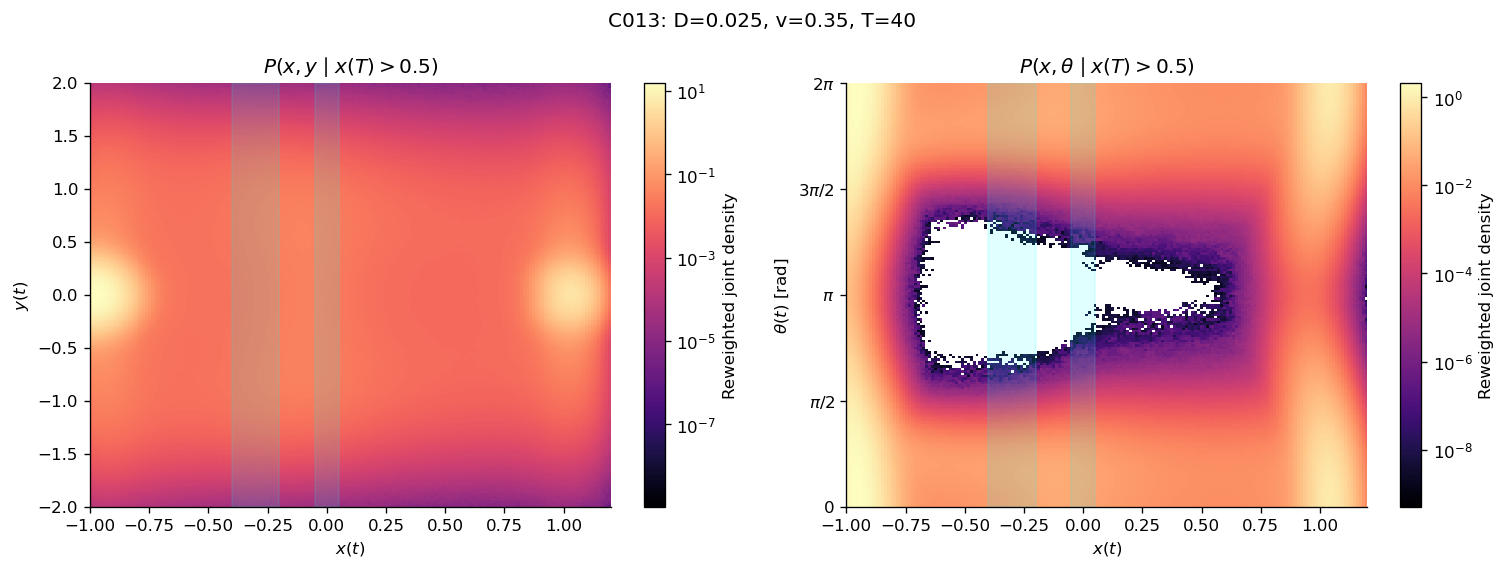

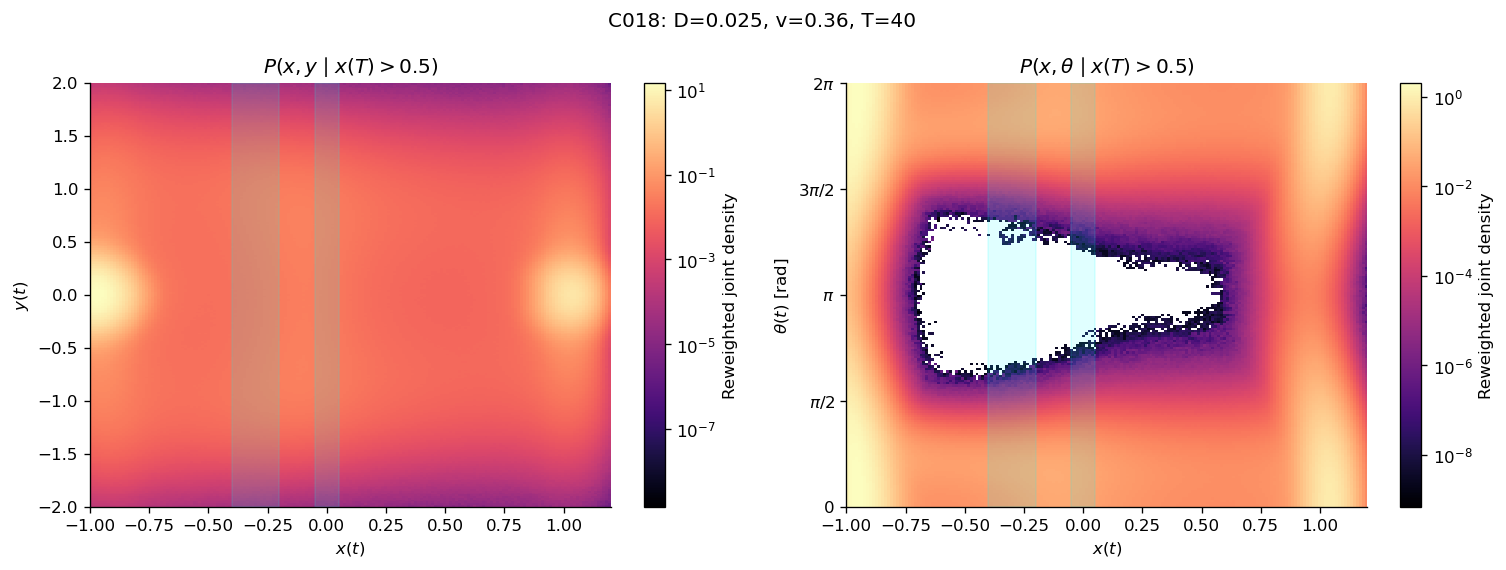

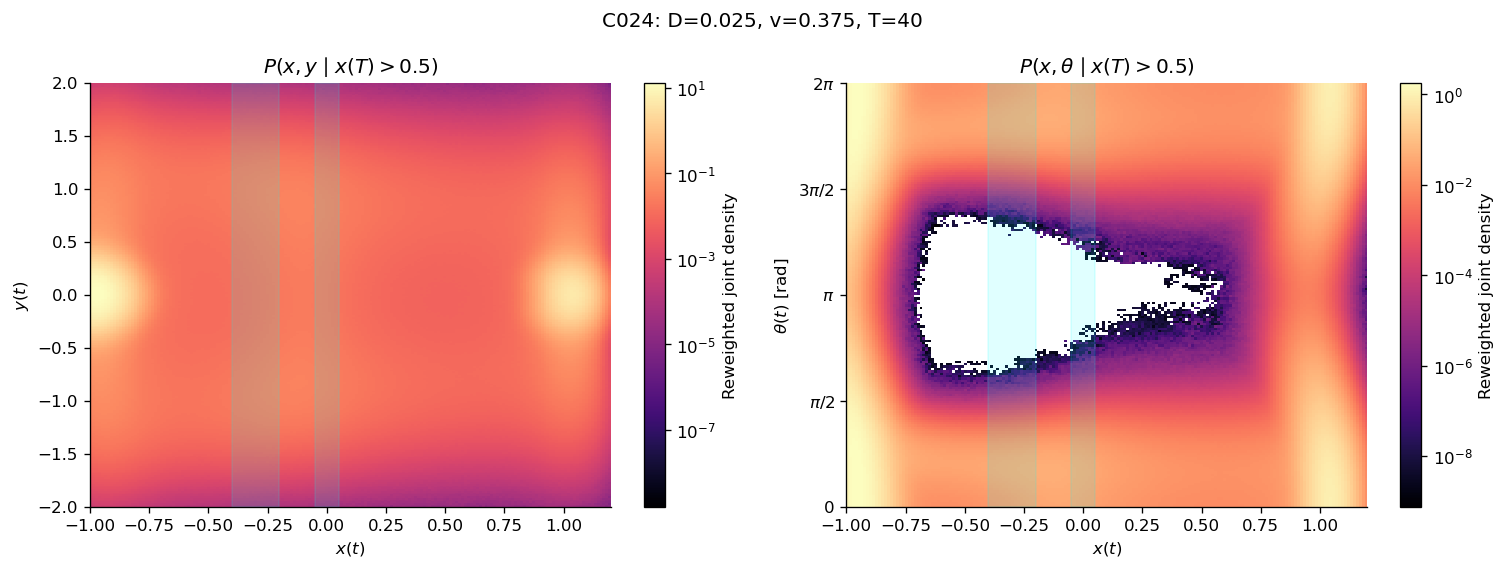

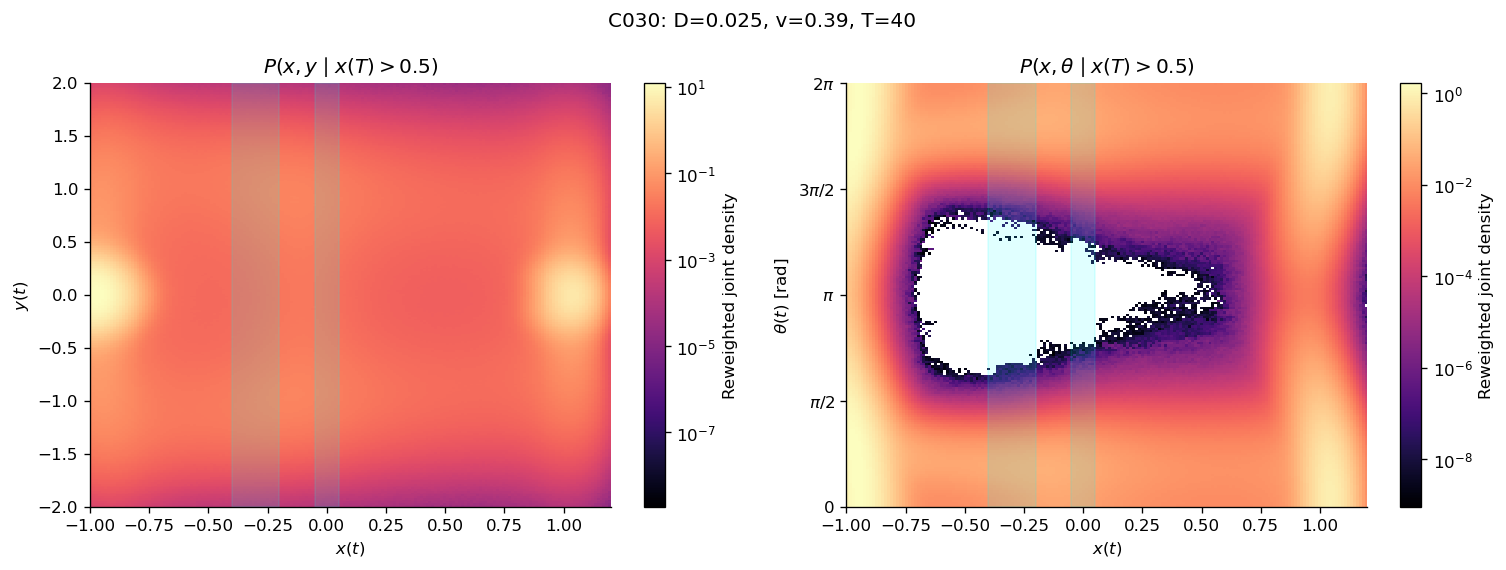

In [9]:
def plot_path_map(ax, product, variable):
    mass = product["pooled_mass"]
    xe, ze = product["x_edges"], product["z_edges"]
    if mass.sum() <= 0:
        ax.text(0.5, 0.5, "No observed mass", transform=ax.transAxes, ha="center")
        return None
    density = mass / mass.sum() / np.diff(xe)[:, None] / np.diff(ze)[None, :]
    positive = density[density > 0]
    norm = None
    if LOG_HEATMAP and positive.size:
        lo, hi = positive.min(), positive.max()
        norm = LogNorm(vmin=lo, vmax=hi if hi > lo else lo * 1.01)
    shown = np.ma.masked_less_equal(density, 0) if LOG_HEATMAP else density
    ax.grid(False)
    mesh = ax.pcolormesh(xe, ze, shown.T, shading="flat", cmap="magma", norm=norm)
    for name, (lo, hi) in X_SLICES.items():
        ax.axvspan(lo, hi, color="cyan", alpha=0.12)
    if X_DISPLAY is not None:
        ax.set_xlim(*X_DISPLAY)
    ax.set_xlabel(r"$x(t)$")
    if variable == "theta":
        theta_axis(ax, "y")
        ax.set_ylabel(r"$\theta(t)$ [rad]")
    else:
        ax.set_ylabel(r"$y(t)$")
        if Y_DISPLAY is not None:
            ax.set_ylim(*Y_DISPLAY)
    return mesh


for case in DETAIL_CASES:
    if not any(case["case_id"] in PATH_DATA[v] for v in PATH_DATA):
        continue
    fig, axes = plt.subplots(1, 2, figsize=(12.8, 4.8))
    for ax, variable in zip(axes, ["y", "theta"]):
        product = PATH_DATA[variable].get(case["case_id"])
        if product is None:
            ax.text(0.5, 0.5, "Not saved", transform=ax.transAxes, ha="center")
        else:
            mesh = plot_path_map(ax, product, variable)
            if mesh is not None:
                fig.colorbar(mesh, ax=ax, label="Reweighted joint density")
        ax.set_title(rf"$P(x,{variable}\mid x(T)>0.5)$" if variable == "y"
                     else r"$P(x,\theta\mid x(T)>0.5)$")
    fig.suptitle(case["label"])
    finish_figure(fig, f"{case['case_id']}_xy_xtheta_maps")


## 10. Path marginals and $x$-slice PDFs with error bands

`all_saved_x` integrates over all saved $x$ bins. The other figures compare the
chosen slices across cases. Both $y$ and $\theta$ PDFs integrate to one in their
saved variable range, whenever the slice contains observed mass.


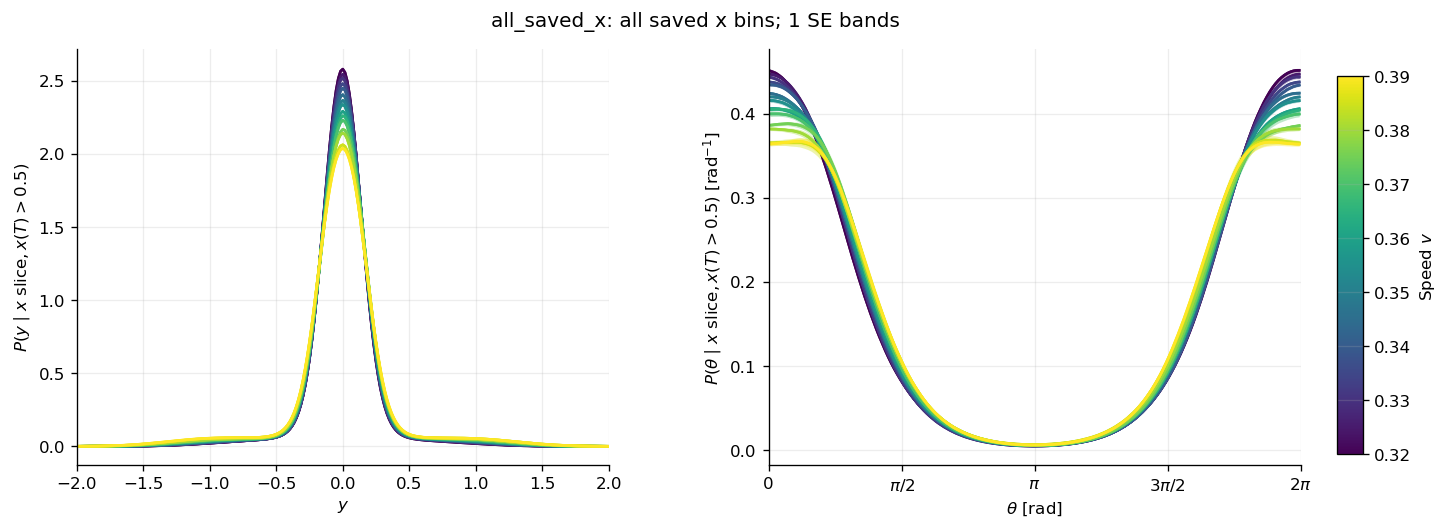

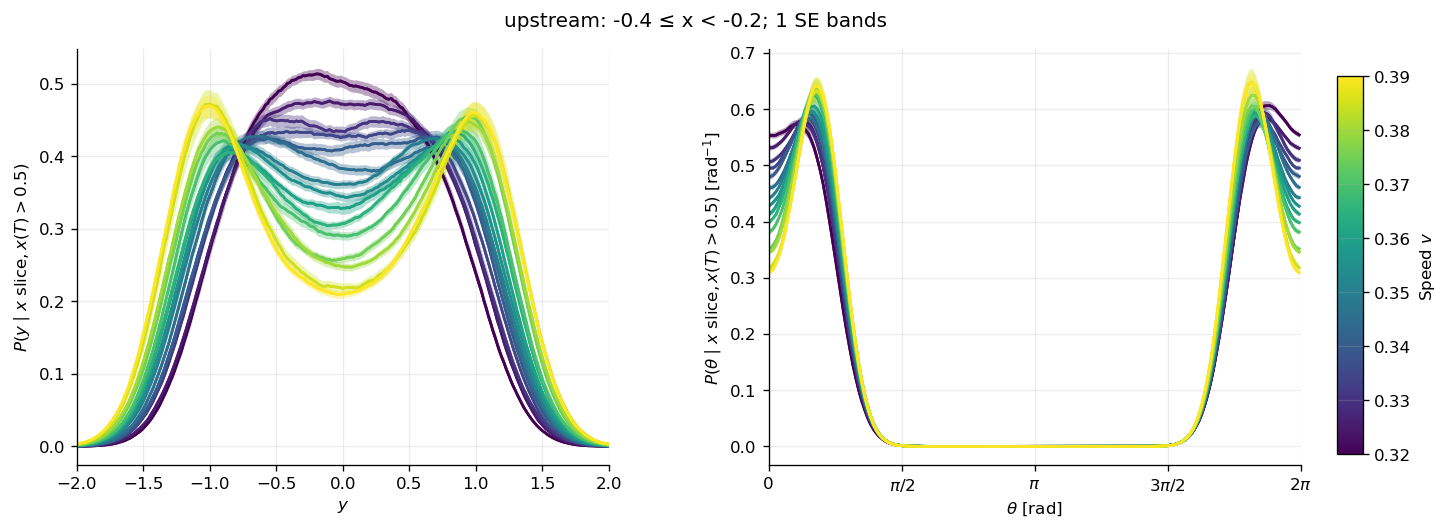

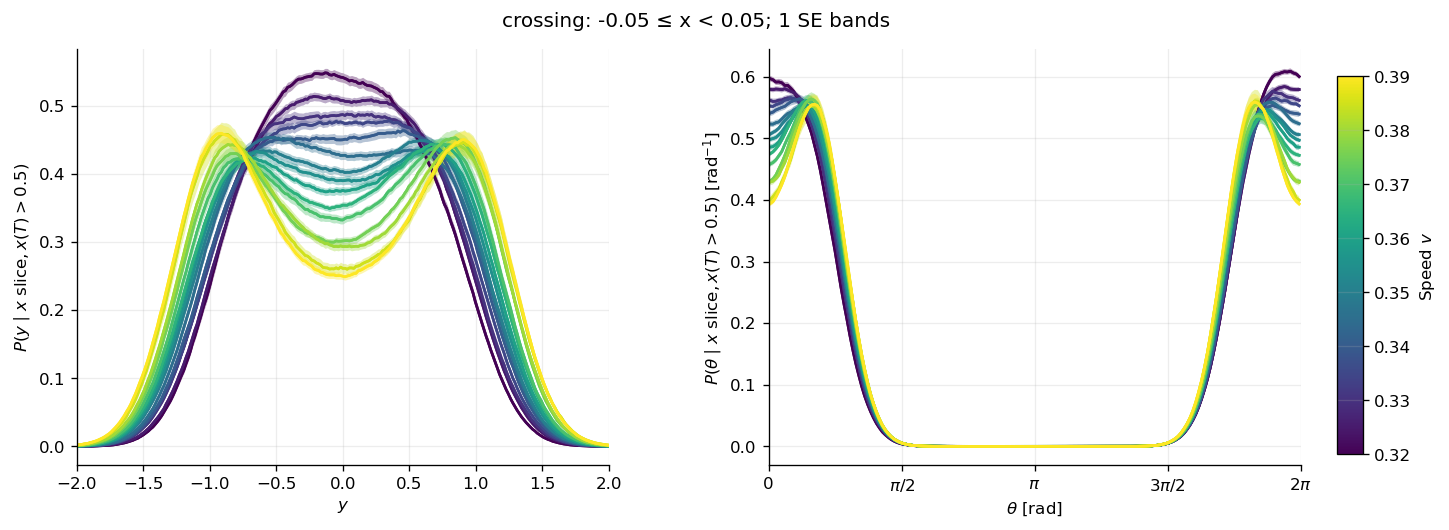

In [10]:
for name in ["all_saved_x", *X_SLICES]:
    if not any(name in product["pdfs"] for products in PATH_DATA.values() for product in products.values()):
        continue
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, variable in zip(axes, ["y", "theta"]):
        for case in CASES:
            product = PATH_DATA[variable].get(case["case_id"])
            if product is not None and name in product["pdfs"]:
                add_pdf(ax, product["pdfs"][name], case, label="_")
        if variable == "theta":
            theta_axis(ax)
            ax.set(xlabel=r"$\theta$ [rad]", ylabel=r"$P(\theta\mid x\ \mathrm{slice},x(T)>0.5)$ [rad$^{-1}$]")
        else:
            ax.set(xlabel=r"$y$", ylabel=r"$P(y\mid x\ \mathrm{slice},x(T)>0.5)$")
            if Y_DISPLAY is not None:
                ax.set_xlim(*Y_DISPLAY)
        if not ax.lines:
            ax.text(0.5, 0.5, "Not saved", transform=ax.transAxes, ha="center")
    slice_title = f"{X_SLICES[name][0]:g} ≤ x < {X_SLICES[name][1]:g}" if name in X_SLICES else "all saved x bins"
    fig.suptitle(f"{name}: {slice_title}; {BAND_SIGMA:g} SE bands")
    add_speed_colorbar(fig, axes)
    finish_figure(fig, f"path_slice_{name}_y_theta")

## 11. Active work by first-crossing ordinate and route

Julia has already measured the complete-path active propulsion work, with unit mobility,

$$W_a=v\sum_k \left[\cos\!\left(\frac{\theta_k+\theta_{k+1}}2\right)\Delta x_k
+\sin\!\left(\frac{\theta_k+\theta_{k+1}}2\right)\Delta y_k\right].$$

The route coordinate is $m=y(\tau_c)$ at the first left-to-right crossing of $x=0$,
conditioned on $x(T)>0.5$. `flat`: $|m|\le M_{\rm CUT}$; `upper_sb`: $m>M_{\rm CUT}$;
`lower_sb`: $m<-M_{\rm CUT}$; `combined_sb`: $|m|>M_{\rm CUT}$. Cuts use the saved
$m$-bin centers. The combined route overlaps the upper and lower routes; do not add
all four route fractions.

The work moments support route means and dispersions, not a full $P(W_a)$ histogram.
`weighted_std_active_work` describes trajectory-to-trajectory spread; the plotted
`chain_jackknife_se` estimates uncertainty in the **mean**. `weight_only_ess` is
$(\sum w)^2/\sum w^2$ and does not correct for MCMC autocorrelation.


In [11]:
M_CUT = 1
def load_work_products(case):
    with h5py.File(case["file"], "r") as h5:
        ids = chain_ids(h5)
        if not ids or not case["has_work"]:
            note(case, "Active-work chain moments unavailable; section skipped.")
            return None
        edges = checked_edges(h5, "active_work/crossing_y_bins")
        m = (edges[:-1] + edges[1:]) / 2
        arrays = {}
        for field in ["mass", "mass2", "sum_W", "sum_W2"]:
            arrays[field] = np.stack([vector(h5, f"chain_statistics/chains/{c}/active_work/unbiased/{field}") for c in ids])
            if arrays[field].shape != (len(ids), len(m)):
                raise ValueError(f"Work field {field} does not match crossing-y bins")
    mass, mass2, sum_w, sum_w2 = (arrays[k] for k in ["mass", "mass2", "sum_W", "sum_W2"])
    mean, se = jackknife_ratio(sum_w, mass)
    scale = case["v"]**2 * case["T"]
    scale = scale if scale > 0 else np.nan
    if not np.isfinite(scale):
        note(case, "v²T is zero; normalized work is undefined (raw work is retained).")
    total = mass.sum(axis=0)
    second = np.divide(sum_w2.sum(axis=0), total, out=np.full_like(total, np.nan), where=total > 0)
    m2 = mass2.sum(axis=0)
    ess = np.divide(total**2, m2, out=np.full_like(total, np.nan), where=m2 > 0)
    profile = pd.DataFrame(dict(
        crossing_y_center=m, mean_active_work=mean, chain_jackknife_se=se,
        mean_normalized_active_work=mean / scale, normalized_chain_jackknife_se=se / scale,
        weighted_std_active_work=np.sqrt(np.maximum(0, second - mean**2)),
        weight_only_ess=ess, n_chains_with_mass=(mass > 0).sum(axis=0),
    ))
    masks = {"flat": np.abs(m) <= M_CUT, "upper_sb": m > M_CUT,
             "lower_sb": m < -M_CUT, "combined_sb": np.abs(m) > M_CUT}
    rows = []
    for route, mask in masks.items():
        den = mass[:, mask].sum(axis=1)
        num = sum_w[:, mask].sum(axis=1)
        value, err = jackknife_ratio(num, den)
        fraction, fraction_se = jackknife_ratio(den, mass.sum(axis=1))
        total_mass = den.sum()
        square_mass = mass2[:, mask].sum()
        std = np.sqrt(max(0, sum_w2[:, mask].sum() / total_mass - float(value)**2)) if total_mass > 0 else np.nan
        rows.append(dict(
            case_id=case["case_id"], file=str(case["file"]), D=case["D"], v=case["v"], T=case["T"],
            route=route, m_cut=M_CUT, n_crossing_y_bins=int(mask.sum()),
            n_chains_total=len(ids), n_chains_with_mass=int(np.count_nonzero(den)),
            largest_chain_mass_fraction=den.max() / total_mass if total_mass > 0 else np.nan,
            route_fraction=float(fraction), route_fraction_se=float(fraction_se) if total_mass > 0 else np.nan,
            unbiased_mass=total_mass, weight_only_ess=total_mass**2 / square_mass if square_mass > 0 else np.nan,
            mean_active_work=float(value), chain_jackknife_se=float(err), weighted_std_active_work=std,
            mean_normalized_active_work=float(value) / scale, normalized_chain_jackknife_se=float(err) / scale,
        ))
    return profile, pd.DataFrame(rows)


WORK_PROFILES, route_tables = {}, []
for case in CASES:
    product = load_work_products(case)
    if product is None:
        continue
    profile, routes = product
    WORK_PROFILES[case["case_id"]] = profile
    route_tables.append(routes)
    export_table(profile, f"{case['case_id']}_active_work_vs_crossing_y")
ROUTE_WORK = pd.concat(route_tables, ignore_index=True) if route_tables else pd.DataFrame()
display(ROUTE_WORK)
export_table(ROUTE_WORK, "active_work_route_summary")


,case_id,file,D,v,T,route,m_cut,n_crossing_y_bins,n_chains_total,n_chains_with_mass,largest_chain_mass_fraction,route_fraction,route_fraction_se,unbiased_mass,weight_only_ess,mean_active_work,chain_jackknife_se,weighted_std_active_work,mean_normalized_active_work,normalized_chain_jackknife_se
0,C001,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...,0.025,0.32,40.0,flat,1,121,128,128,0.080178,0.918763,0.001856,1.059159e-06,225223.146680,0.630276,0.000411,0.106651,0.153876,0.000100
1,C001,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...,0.025,0.32,40.0,upper_sb,1,60,128,128,0.099822,0.038149,0.001632,4.397814e-08,9852.621144,0.608385,0.005269,0.177174,0.148532,0.001286
2,C001,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...,0.025,0.32,40.0,lower_sb,1,60,128,128,0.074295,0.043088,0.001738,4.967217e-08,11154.533288,0.598997,0.006022,0.178889,0.146239,0.001470
3,C001,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...,0.025,0.32,40.0,combined_sb,1,120,128,128,0.086283,0.081237,0.001856,9.365032e-08,21007.125378,0.603406,0.005156,0.178147,0.147316,0.001259
4,C002,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...,0.025,0.32,40.0,flat,1,121,128,128,0.080178,0.918763,0.001856,1.059159e-06,225223.146680,0.630276,0.000411,0.106651,0.153876,0.000100
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,C029,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...,0.025,0.39,40.0,combined_sb,1,120,128,128,0.081560,0.279529,0.003737,1.376493e-05,74096.988967,0.800815,0.005014,0.230268,0.131626,0.000824
116,C030,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...,0.025,0.39,40.0,flat,1,121,128,128,0.076389,0.720471,0.003737,3.547834e-05,184679.762111,0.800692,0.000561,0.149052,0.131606,0.000092
117,C030,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...,0.025,0.39,40.0,upper_sb,1,60,128,128,0.071167,0.135848,0.004626,6.689593e-06,35949.460887,0.800267,0.005316,0.229848,0.131536,0.000874
118,C030,/home/nst/amarin/Desktop/ABP_Rare_Events/ABPNo...,0.025,0.39,40.0,lower_sb,1,60,128,128,0.091386,0.143681,0.005467,7.075338e-06,38147.728434,0.801333,0.005360,0.230663,0.131711,0.000881


## 12. Work comparisons across noise levels or speeds

Each curve keeps the other sweep parameter and $T$ fixed. Repeated files at the same
parameter value are shown as separate points. Route fractions are relative to the
sampled work trajectories with a recorded crossing in the saved $m$ range; consult
`work_no_crossing` and `work_crossing_y_out` in the inventory.


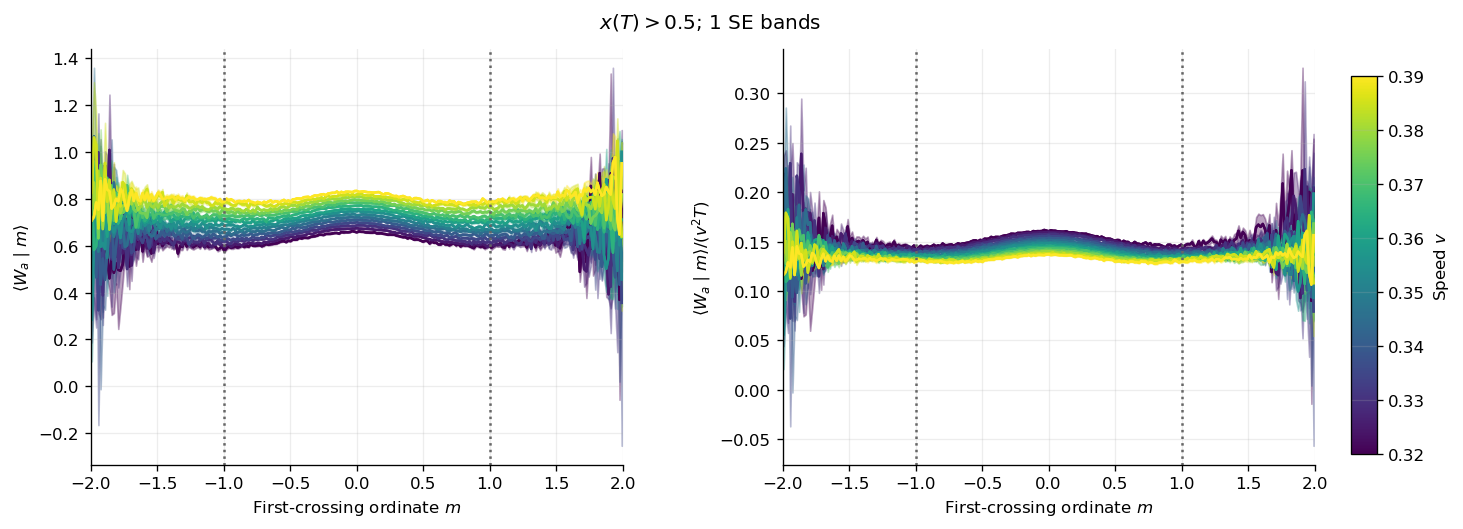

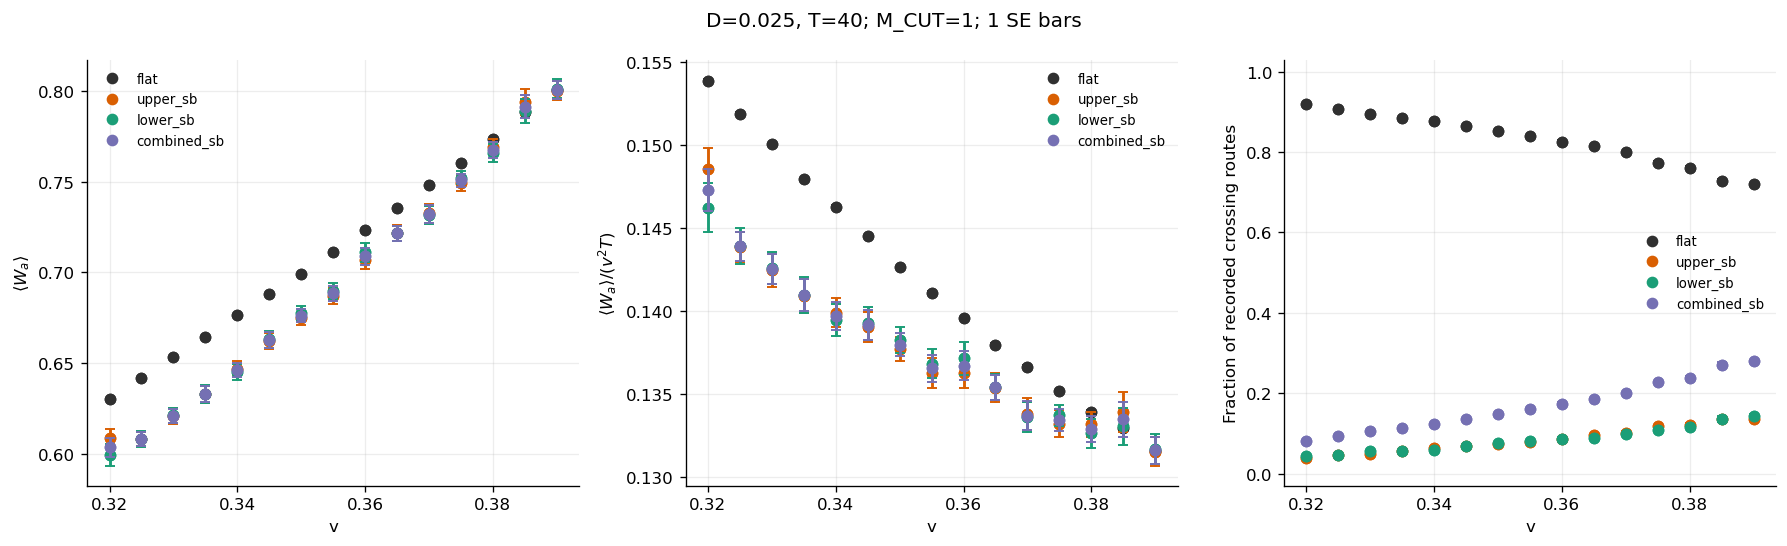

In [12]:
if WORK_PROFILES:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for case in CASES:
        table = WORK_PROFILES.get(case["case_id"])
        if table is None:
            continue
        for ax, col, secol in [
            (axes[0], "mean_active_work", "chain_jackknife_se"),
            (axes[1], "mean_normalized_active_work", "normalized_chain_jackknife_se"),
        ]:
            xx, yy, err = (table[k].to_numpy() for k in ["crossing_y_center", col, secol])
            color = CASE_COLORS[case["case_id"]]
            ax.plot(xx, yy, color=color)
            ax.fill_between(xx, yy - BAND_SIGMA * err, yy + BAND_SIGMA * err, color=color, alpha=0.20)
    for ax in axes:
        ax.axvline(-M_CUT, color="0.4", ls=":")
        ax.axvline(M_CUT, color="0.4", ls=":")
        ax.set_xlabel(r"First-crossing ordinate $m$")
        if Y_DISPLAY is not None:
            ax.set_xlim(*Y_DISPLAY)
    axes[0].set_ylabel(r"$\langle W_a\mid m\rangle$")
    axes[1].set_ylabel(r"$\langle W_a\mid m\rangle/(v^2T)$")
    fig.suptitle(rf"$x(T)>0.5$; {BAND_SIGMA:g} SE bands")
    add_speed_colorbar(fig, axes)
    finish_figure(fig, "active_work_vs_crossing_y")

ROUTE_COLORS = {"flat": "#303030", "upper_sb": "#D95F02", "lower_sb": "#1B9E77", "combined_sb": "#7570B3"}
if not ROUTE_WORK.empty:
    fixed = ["D", "T"] if SWEEP_PARAMETER == "v" else ["v", "T"]
    for fixed_values, group in ROUTE_WORK.groupby(fixed, sort=True):
        group_title = ", ".join(f"{name}={value:g}" for name, value in zip(fixed, fixed_values))
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
        specifications = [
            ("mean_active_work", "chain_jackknife_se", r"$\langle W_a\rangle$"),
            ("mean_normalized_active_work", "normalized_chain_jackknife_se", r"$\langle W_a\rangle/(v^2T)$"),
            ("route_fraction", "route_fraction_se", "Fraction of recorded crossing routes"),
        ]
        for route, color in ROUTE_COLORS.items():
            table = group[group["route"] == route].sort_values(SWEEP_PARAMETER)
            line_style = "none" if table[SWEEP_PARAMETER].duplicated().any() else "-"
            for ax, (col, secol, ylabel) in zip(axes, specifications):
                xx, yy, err = (table[k].to_numpy() for k in [SWEEP_PARAMETER, col, secol])
                valid = np.isfinite(xx) & np.isfinite(yy)
                ax.plot(xx[valid], yy[valid], marker="o", ls=line_style, color=color, label=route)
                with_se = valid & np.isfinite(err)
                if with_se.any():
                    ax.errorbar(xx[with_se], yy[with_se], yerr=BAND_SIGMA * err[with_se], fmt="none", color=color, capsize=3)
                ax.set(xlabel=SWEEP_PARAMETER, ylabel=ylabel)
        for ax in axes:
            ax.legend(fontsize=8)
            ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
            ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
        axes[2].set_ylim(-0.03, 1.03)
        fig.suptitle(f"{group_title}; M_CUT={M_CUT:g}; {BAND_SIGMA:g} SE bars")
        finish_figure(fig, f"route_work_vs_{SWEEP_PARAMETER}_{group_title}")

## 13. Inspect the actual saved $\theta(t)$ sequences

For each retained example trajectory, Julia stores
`saved_trajectories/x_gt_0p5/<j>/thetas`. These angles are already wrapped.
The time grid is $t_i=i\,\mathrm{dt}\times\mathrm{saved\_path\_time\_thin}$ for
$i=0,1,\ldots$; thinning need not retain the final integration point.
The examples are capped diagnostics, not a representative sample for PDF error bars.
Connecting points across a $2\pi$ wrap is avoided by displaying markers.


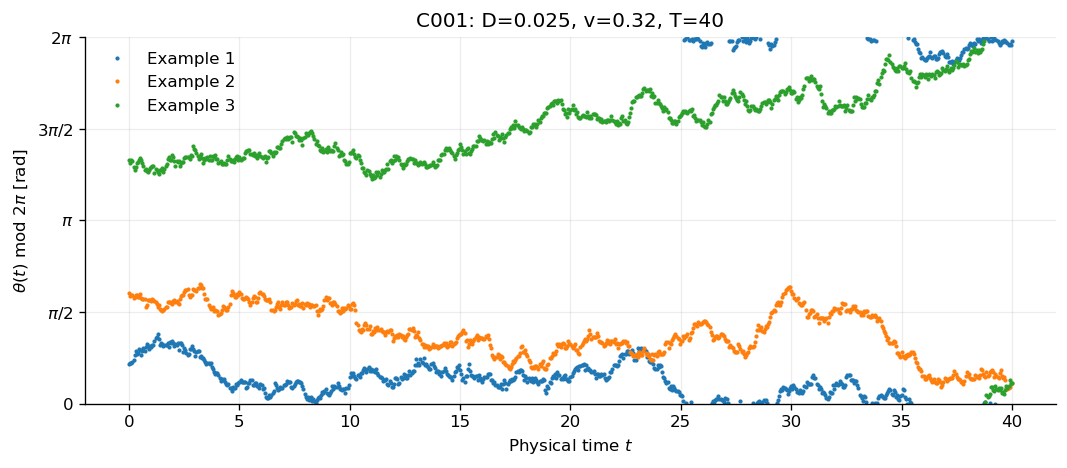

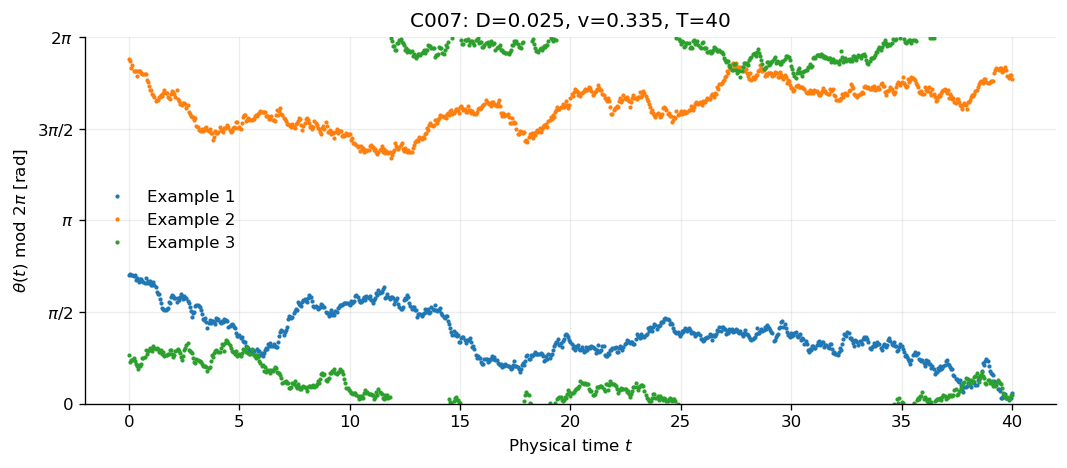

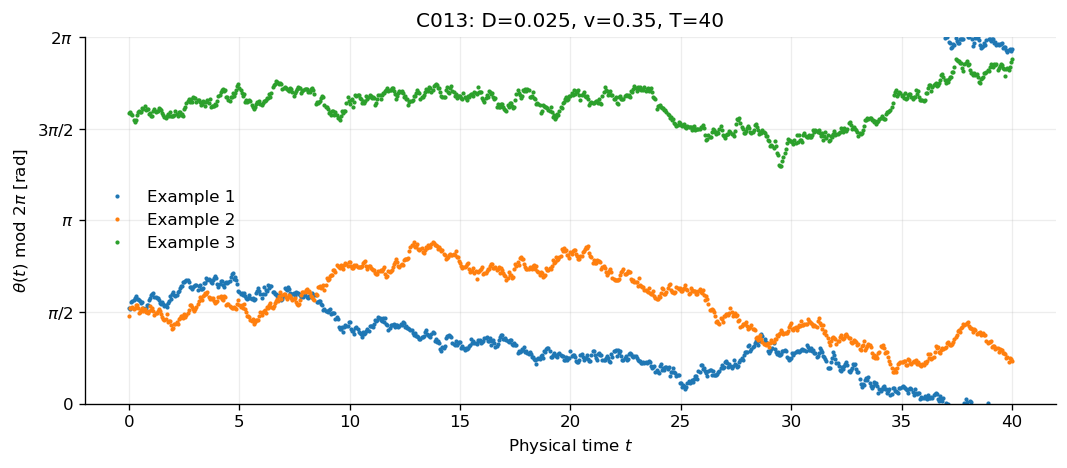

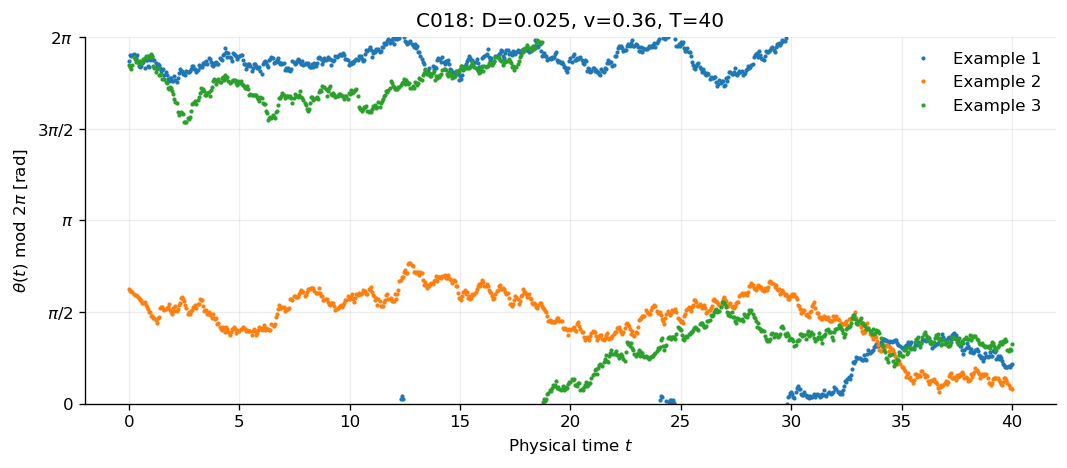

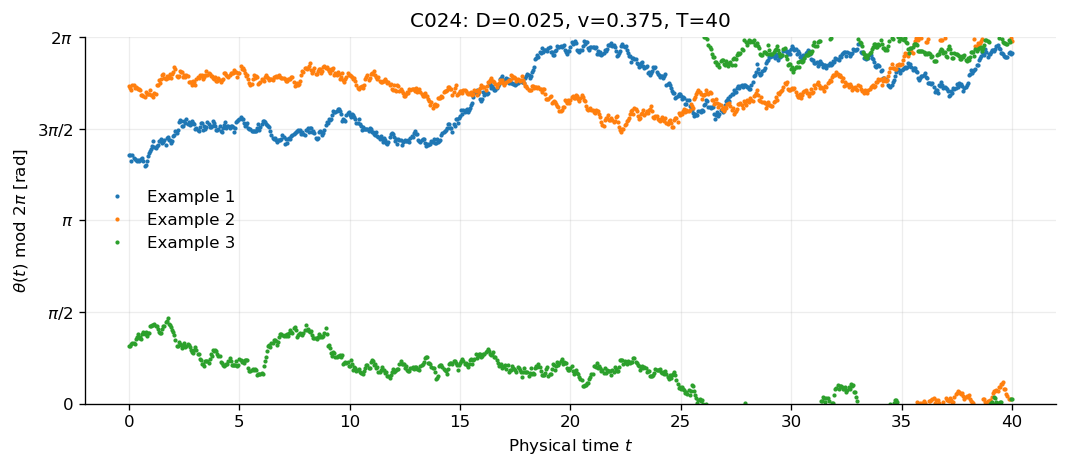

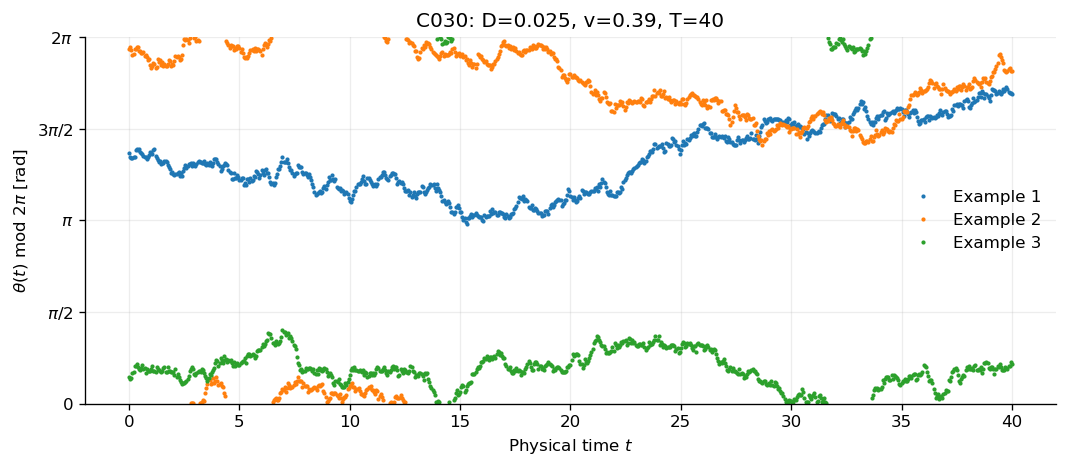

In [13]:
for case in DETAIL_CASES:
    with h5py.File(case["file"], "r") as h5:
        base = "saved_trajectories/x_gt_0p5"
        if base not in h5:
            note(case, "No saved example trajectories for x(T)>0.5.")
            continue
        ids = sorted([key for key in h5[base].keys() if str(key).isdigit()], key=int)
        saved = [(j, vector(h5, f"{base}/{j}/thetas")) for j in ids[:MAX_EXAMPLE_PATHS]
                 if f"{base}/{j}/thetas" in h5]
        dt, thin = scalar(h5, "metadata/dt"), scalar(h5, "metadata/saved_path_time_thin")
    if not saved:
        note(case, "Saved examples contain no thetas arrays.")
        continue
    if not np.isfinite(dt * thin) or dt <= 0 or thin < 1:
        note(case, "Example theta arrays found, but their time-grid metadata is missing.")
        continue
    fig, ax = plt.subplots(figsize=(9, 4))
    for j, theta in saved:
        t = np.arange(len(theta)) * dt * thin
        ax.plot(t, theta, ".", ms=3, label=f"Example {j}")
    theta_axis(ax, "y")
    ax.set(xlabel=r"Physical time $t$", ylabel=r"$\theta(t)\ \mathrm{mod}\ 2\pi$ [rad]", title=case["label"])
    ax.legend()
    finish_figure(fig, f"{case['case_id']}_saved_theta_paths")


## 14. Output files and exact Julia storage locations

The full orientation of the current MCMC trajectory is `sys.θs[k]`, aligned with
`sys.xs[k]` at $t=(k-1)\,\mathrm{dt}$ (Julia uses 1-based indexing).

| Step | Julia location | What happens |
| --- | --- | --- |
| Allocate and integrate | `src/model.jl`, `ABPTrajectory` and `integrate!` | Holds the unwrapped vector `θs`; fills `sys.θs[time_index + 1]`. |
| Sample production paths | `src/production.jl`, `abp_run_production_chain!` | Uses `path_observation_stride`, endpoint windows, and `path_time_stride`. |
| Accumulate the joint histogram | `src/production_accumulators.jl`, `abp_add_path_point_conditioned_windows!` | Applies `x > path_x_min`, wraps with `mod2pi(theta)`, and increments `counts_path_xtheta_biased` / `counts_path_xtheta_unbiased`. |
| Retain an example path | `src/production_accumulators.jl`, `abp_maybe_save_path!` | Copies `thetas = mod2pi.(sys.θs[inds])`. |
| Write to disk | `src/io.jl`, `abp_save_case_jld2` | Writes the datasets below. |

| JLD2 key | Content |
| --- | --- |
| `histograms/bins_path_x` | Path-$x$ edges |
| `histograms/bins_path_theta` | Angular edges in radians |
| `path_endpoint_conditions/x_gt_0p5/unbiased/path_x_theta` | Pooled reweighted **masses** (normalize to obtain a PDF) |
| `path_endpoint_conditions/x_gt_0p5/biased/path_x_theta` | Pooled biased counts |
| `chain_statistics/chains/<c>/path_endpoint_conditions/x_gt_0p5/unbiased/path_x_theta_flat_julia_column_major` | Chain masses used for error bars |
| `chain_statistics/chains/<c>/path_endpoint_conditions/x_gt_0p5/unbiased/path_x_theta_shape` | Shape `(n_x_bins, n_theta_bins)` |
| `saved_trajectories/<window>/<j>/thetas` | Thinned angle sequence of saved example `<j>` |

The standard CSV export of the pooled orientation histogram is
`endpoint_x_gt_0p5_filtered_path_x_theta_long.csv`. The notebook reads JLD2 for the
chain arrays, which are required to obtain the error bands.


In [14]:
print(f"Cases: {len(CASES)}; figures: {len(FIGURES)} files; tables: {len(TABLES)} files")
if SAVE_FIGS or SAVE_TABLES:
    print(f"Output directory: {OUTPUT_DIR.resolve()}")
for path in FIGURES + TABLES:
    print(path.name)
if MESSAGES:
    print("\nUnavailable or limited data:")
    for message in MESSAGES:
        print(" -", message)


Cases: 30; figures: 40 files; tables: 333 files
Output directory: /home/nst/amarin/Desktop/ABP_Rare_Events/ABPNoiseSweep/data/plots_production_errors_work_theta
muca_production_diagnostics.png
muca_production_diagnostics.pdf
endpoint_pdf_and_relative_error.png
endpoint_pdf_and_relative_error.pdf
conditional_observables_x_gt_0p5.png
conditional_observables_x_gt_0p5.pdf
C001_xy_xtheta_maps.png
C001_xy_xtheta_maps.pdf
C007_xy_xtheta_maps.png
C007_xy_xtheta_maps.pdf
C013_xy_xtheta_maps.png
C013_xy_xtheta_maps.pdf
C018_xy_xtheta_maps.png
C018_xy_xtheta_maps.pdf
C024_xy_xtheta_maps.png
C024_xy_xtheta_maps.pdf
C030_xy_xtheta_maps.png
C030_xy_xtheta_maps.pdf
path_slice_all_saved_x_y_theta.png
path_slice_all_saved_x_y_theta.pdf
path_slice_upstream_y_theta.png
path_slice_upstream_y_theta.pdf
path_slice_crossing_y_theta.png
path_slice_crossing_y_theta.pdf
active_work_vs_crossing_y.png
active_work_vs_crossing_y.pdf
route_work_vs_v_D_0.025_T_40.png
route_work_vs_v_D_0.025_T_40.pdf
C001_saved_theta_